# Day 070 | Transfer Learning (ResNet, VGG)
## 100 Days of ML for Geotechnical Engineering

| | |
|---|---|
| **Author** | Ripon Chandra Malo |
| **Phase** | 4 — Deep Learning |
| **Topic** | Transfer Learning with ResNet18 |
| **Tools** | PyTorch, torchvision, NumPy, Matplotlib |
| **Geo Problem** | Classifying soil crack images using a pretrained ResNet18 (crack / no-crack) |

---

## Concept Overview

| Concept | Description | Geotechnical Benefit |
|---|---|---|
| Transfer Learning | Use a model pretrained on ImageNet for a new task | ResNet18 already knows edges, textures, shapes — relevant for crack detection |
| Feature Extraction | Freeze all layers, replace only the final FC head | Fast training; useful when geo dataset is tiny (<200 images) |
| Fine-Tuning | Unfreeze last layer block, retrain at low LR | Adapts ResNet's high-level features to crack patterns |
| ResNet18 | 18-layer residual network; 11M parameters | Strong image features; manageable compute |
| Residual connection | x + F(x) — shortcut skips layers | Enables very deep networks without vanishing gradients |
| Frozen parameters | `requires_grad=False` | No gradient computed => faster, less data needed |
| `model.fc` | Final fully-connected layer in ResNet18 | Replace with Linear(512, 2) for binary geo task |

---

## Geotechnical Problem Framing

**Soil and concrete crack detection** is a critical geotechnical inspection task. Cracks in:
- Retaining walls, embankments, dam faces — indicate potential failure zones
- Pavements and foundations — reveal differential settlement

Field inspection produces limited labelled photographs (often <500). Training a CNN from scratch requires 10,000+ images. **Transfer learning** lets us use ResNet18's 11 million parameters pre-trained on 1.2 million ImageNet images, then adapt only the final layer to our 64×64 crack vs. no-crack task.

**Three strategies compared**:
1. **Scratch** — train ResNet18 from random weights (poor baseline)
2. **Feature Extraction** — freeze all, train only new FC head
3. **Fine-Tuning** — freeze early layers, train last ResNet block + FC head

---
## Part 1 | Setup & Synthetic Crack Image Generator

In [1]:
# ─────────────────────────────────────────────────────────
# PART 1 — Setup & Synthetic 64×64 RGB Crack Images
# ─────────────────────────────────────────────────────────
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import time
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(42)
np.random.seed(42)

IMG_SIZE  = 64
N_PER_CLS = 80    # images per class (160 total — very small dataset)

def make_crack_image():
    """
    Crack image: noisy concrete-like background with a dark diagonal/horizontal line crack.
    """
    # Concrete background: medium grey with texture
    img = np.random.uniform(0.45, 0.65, (IMG_SIZE, IMG_SIZE, 3)).astype(np.float32)
    img += np.random.normal(0, 0.05, img.shape)

    # Draw 1–3 crack lines
    n_cracks = np.random.randint(1, 4)
    for _ in range(n_cracks):
        crack_type = np.random.choice(['horizontal', 'diagonal', 'vertical'])
        width_px   = np.random.randint(1, 3)
        intensity  = np.random.uniform(0.05, 0.20)   # dark crack

        if crack_type == 'horizontal':
            row = np.random.randint(10, IMG_SIZE - 10)
            c_start = np.random.randint(0, IMG_SIZE // 4)
            c_end   = np.random.randint(3 * IMG_SIZE // 4, IMG_SIZE)
            for w in range(width_px):
                if row + w < IMG_SIZE:
                    img[row + w, c_start:c_end, :] = intensity
        elif crack_type == 'vertical':
            col = np.random.randint(10, IMG_SIZE - 10)
            r_start = np.random.randint(0, IMG_SIZE // 4)
            r_end   = np.random.randint(3 * IMG_SIZE // 4, IMG_SIZE)
            for w in range(width_px):
                if col + w < IMG_SIZE:
                    img[r_start:r_end, col + w, :] = intensity
        else:  # diagonal
            r_start = np.random.randint(0, IMG_SIZE // 3)
            c_start = np.random.randint(0, IMG_SIZE // 3)
            length  = np.random.randint(20, 45)
            slope   = np.random.uniform(0.3, 1.5)
            for i in range(length):
                r = int(r_start + i)
                c = int(c_start + i * slope)
                if 0 <= r < IMG_SIZE and 0 <= c < IMG_SIZE:
                    img[r, c, :] = intensity

    return np.clip(img, 0, 1)

def make_nocrack_image():
    """
    No-crack image: random noise texture simulating intact concrete/soil surface.
    """
    img   = np.random.uniform(0.4, 0.7, (IMG_SIZE, IMG_SIZE, 3)).astype(np.float32)
    # Add coarse texture (simulate aggregate surface)
    coarse = np.random.randint(0, IMG_SIZE // 8, (20, 2))
    for ry, cx in coarse:
        ry_full = ry * 8 + np.random.randint(0, 8)
        cx_full = cx * 8 + np.random.randint(0, 8)
        r_patch = np.random.randint(2, 6)
        color   = np.random.uniform(0.35, 0.75)
        for dr in range(-r_patch, r_patch):
            for dc in range(-r_patch, r_patch):
                if dr**2 + dc**2 <= r_patch**2:
                    rr, cc = ry_full + dr, cx_full + dc
                    if 0 <= rr < IMG_SIZE and 0 <= cc < IMG_SIZE:
                        img[rr, cc, :] = color
    img += np.random.normal(0, 0.04, img.shape)
    return np.clip(img, 0, 1)

# Generate dataset
crack_imgs    = np.array([make_crack_image()    for _ in range(N_PER_CLS)])
nocrack_imgs  = np.array([make_nocrack_image()  for _ in range(N_PER_CLS)])

all_images = np.concatenate([crack_imgs, nocrack_imgs], axis=0)  # (160, 64, 64, 3)
all_labels = np.array([1]*N_PER_CLS + [0]*N_PER_CLS)            # 1=crack, 0=no-crack

perm = np.random.permutation(2 * N_PER_CLS)
all_images, all_labels = all_images[perm], all_labels[perm]

print(f"Dataset: {all_images.shape}  (64×64 RGB)")
print(f"Labels:  {np.bincount(all_labels)} (0=no-crack, 1=crack)")

Dataset: (160, 64, 64, 3)  (64×64 RGB)
Labels:  [80 80] (0=no-crack, 1=crack)


---
## Part 2 | Visualise Sample Images

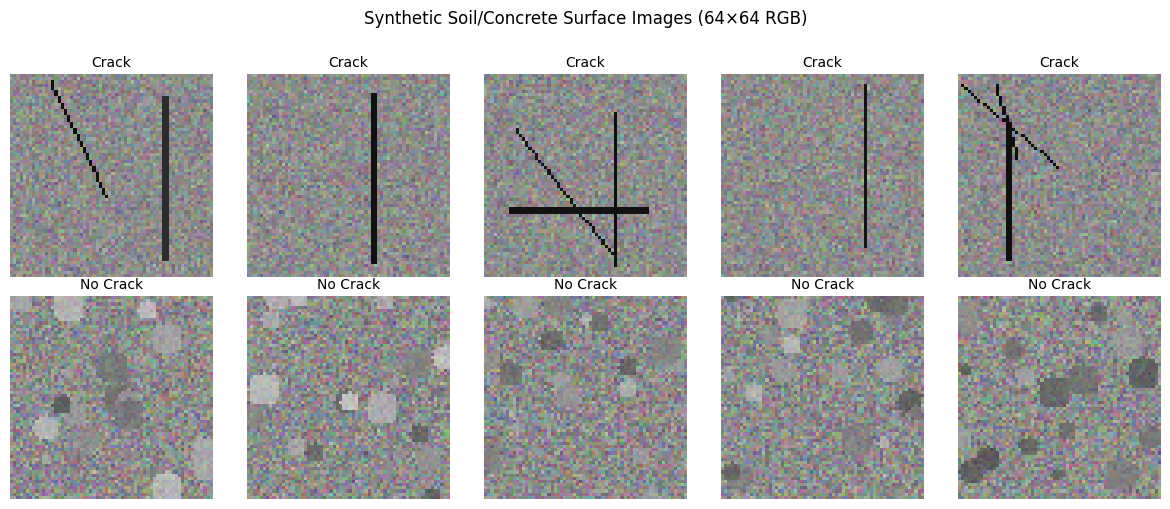

Crack images:    dark line patterns (horizontal, vertical, diagonal)
No-crack images: random aggregate texture — no directional dark lines


In [2]:
# ─────────────────────────────────────────────────────────
# PART 2 — Visualise Crack vs No-Crack Images
# ─────────────────────────────────────────────────────────

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes[0]):
    ax.imshow(np.clip(crack_imgs[i], 0, 1))
    ax.set_title('Crack', fontsize=10)
    ax.axis('off')
for i, ax in enumerate(axes[1]):
    ax.imshow(np.clip(nocrack_imgs[i], 0, 1))
    ax.set_title('No Crack', fontsize=10)
    ax.axis('off')

plt.suptitle('Synthetic Soil/Concrete Surface Images (64×64 RGB)', y=1.01)
plt.tight_layout()
plt.show()

print("Crack images:    dark line patterns (horizontal, vertical, diagonal)")
print("No-crack images: random aggregate texture — no directional dark lines")

---
## Part 3 | DataLoader & ImageNet Normalisation

In [3]:
# ─────────────────────────────────────────────────────────
# PART 3 — DataLoader with ImageNet Normalisation
# ─────────────────────────────────────────────────────────

# PyTorch expects (B, C, H, W) in float32
# images are currently (N, H, W, C) => transpose
X_raw = torch.tensor(all_images, dtype=torch.float32).permute(0, 3, 1, 2)  # (160, 3, 64, 64)
y_raw = torch.tensor(all_labels, dtype=torch.long)

# Apply ImageNet normalisation (mean and std from ImageNet)
# ResNet18 was trained with these exact statistics
imagenet_mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
imagenet_std  = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
X_norm        = (X_raw - imagenet_mean) / imagenet_std

# Train: 128 / Test: 32
split  = 128
X_tr   = X_norm[:split];  y_tr = y_raw[:split]
X_te   = X_norm[split:];  y_te = y_raw[split:]

tr_loader = DataLoader(TensorDataset(X_tr, y_tr), batch_size=16, shuffle=True)
te_loader = DataLoader(TensorDataset(X_te, y_te), batch_size=16)

print(f"Input tensor shape: {X_norm.shape}")
print(f"Training: {len(X_tr)} | Test: {len(X_te)}")
print(f"\nImageNet normalisation applied:")
print(f"  Means: [0.485, 0.456, 0.406]  (R, G, B)")
print(f"  Stds:  [0.229, 0.224, 0.225]")
print(f"  This is required for pretrained ResNet18 to produce meaningful features.")

Input tensor shape: torch.Size([160, 3, 64, 64])
Training: 128 | Test: 32

ImageNet normalisation applied:
  Means: [0.485, 0.456, 0.406]  (R, G, B)
  Stds:  [0.229, 0.224, 0.225]
  This is required for pretrained ResNet18 to produce meaningful features.


---
## Part 4 | Loading Pretrained ResNet18

In [4]:
# ─────────────────────────────────────────────────────────
# PART 4 — Load Pretrained ResNet18
# ─────────────────────────────────────────────────────────
import torchvision.models as models

# Load ResNet18 with ImageNet-pretrained weights
# torchvision >= 0.13: use weights=models.ResNet18_Weights.DEFAULT
# torchvision < 0.13:  use pretrained=True
try:
    resnet18 = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    print("Loaded ResNet18 with ResNet18_Weights.DEFAULT")
except AttributeError:
    resnet18 = models.resnet18(pretrained=True)
    print("Loaded ResNet18 with pretrained=True (legacy API)")

# ResNet18 architecture summary
total_params = sum(p.numel() for p in resnet18.parameters())
print(f"\nResNet18 total parameters: {total_params:,}")
print(f"\nResNet18 final layer (fc):")
print(f"  {resnet18.fc}")
print(f"  Input features: {resnet18.fc.in_features}  (512-dim feature vector)")
print(f"  Output classes: {resnet18.fc.out_features} (ImageNet 1000 classes — we will replace this)")

print("\nResNet18 layer groups:")
for name, _ in resnet18.named_children():
    print(f"  {name}")

Loaded ResNet18 with ResNet18_Weights.DEFAULT

ResNet18 total parameters: 11,689,512

ResNet18 final layer (fc):
  Linear(in_features=512, out_features=1000, bias=True)
  Input features: 512  (512-dim feature vector)
  Output classes: 1000 (ImageNet 1000 classes — we will replace this)

ResNet18 layer groups:
  conv1
  bn1
  relu
  maxpool
  layer1
  layer2
  layer3
  layer4
  avgpool
  fc


---
## Part 5 | Strategy 1 — Feature Extraction (Freeze All)

In [5]:
# ─────────────────────────────────────────────────────────
# PART 5 — Feature Extraction: Freeze All, Replace FC
# ─────────────────────────────────────────────────────────
import copy

def build_feature_extractor():
    """Freeze all ResNet18 layers; replace fc with a 2-class head."""
    try:
        model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    except AttributeError:
        model = models.resnet18(pretrained=True)

    # Freeze EVERYTHING
    for param in model.parameters():
        param.requires_grad = False

    # Replace only the final FC layer — this will be trainable
    in_features  = model.fc.in_features    # 512
    model.fc     = nn.Linear(in_features, 2)   # crack vs no-crack

    return model

model_fe = build_feature_extractor()

trainable_fe = sum(p.numel() for p in model_fe.parameters() if p.requires_grad)
total_fe     = sum(p.numel() for p in model_fe.parameters())
print(f"Feature Extraction mode:")
print(f"  Trainable parameters: {trainable_fe:,}  ({100*trainable_fe/total_fe:.1f}% of total)")
print(f"  Frozen parameters:    {total_fe - trainable_fe:,}")
print(f"  New head: Linear(512, 2)")

Feature Extraction mode:
  Trainable parameters: 1,026  (0.0% of total)
  Frozen parameters:    11,176,512
  New head: Linear(512, 2)


---
## Part 6 | Strategy 2 — Fine-Tuning (Unfreeze Last Layer Block)

In [6]:
# ─────────────────────────────────────────────────────────
# PART 6 — Fine-Tuning: Unfreeze layer4 + FC
# ─────────────────────────────────────────────────────────

def build_fine_tuner():
    """Freeze early layers; unfreeze ResNet18's layer4 and fc."""
    try:
        model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    except AttributeError:
        model = models.resnet18(pretrained=True)

    # Freeze all layers first
    for param in model.parameters():
        param.requires_grad = False

    # Unfreeze last residual block (layer4) — adapts high-level features
    for param in model.layer4.parameters():
        param.requires_grad = True

    # Replace and unfreeze fc
    model.fc = nn.Linear(model.fc.in_features, 2)
    # model.fc is newly created => requires_grad=True by default

    return model

model_ft = build_fine_tuner()

trainable_ft = sum(p.numel() for p in model_ft.parameters() if p.requires_grad)
total_ft     = sum(p.numel() for p in model_ft.parameters())
print(f"Fine-Tuning mode:")
print(f"  Trainable parameters: {trainable_ft:,}  ({100*trainable_ft/total_ft:.1f}% of total)")
print(f"  Frozen parameters:    {total_ft - trainable_ft:,}")
print(f"  Unfrozen layers:      layer4 + fc")
print()
print("Unfrozen layer4 parameters by sub-module:")
for name, module in model_ft.layer4.named_modules():
    params = sum(p.numel() for p in module.parameters() if p.requires_grad)
    if params > 0:
        print(f"  layer4.{name}: {params:,} trainable params")

Fine-Tuning mode:
  Trainable parameters: 8,394,754  (75.1% of total)
  Frozen parameters:    2,782,784
  Unfrozen layers:      layer4 + fc

Unfrozen layer4 parameters by sub-module:
  layer4.: 8,393,728 trainable params
  layer4.0: 3,673,088 trainable params
  layer4.0.conv1: 1,179,648 trainable params
  layer4.0.bn1: 1,024 trainable params
  layer4.0.conv2: 2,359,296 trainable params
  layer4.0.bn2: 1,024 trainable params
  layer4.0.downsample: 132,096 trainable params
  layer4.0.downsample.0: 131,072 trainable params
  layer4.0.downsample.1: 1,024 trainable params
  layer4.1: 4,720,640 trainable params
  layer4.1.conv1: 2,359,296 trainable params
  layer4.1.bn1: 1,024 trainable params
  layer4.1.conv2: 2,359,296 trainable params
  layer4.1.bn2: 1,024 trainable params


---
## Part 7 | Training All Three Strategies

In [7]:
# ─────────────────────────────────────────────────────────
# PART 7 — Train & Compare: Scratch vs Feature Extraction vs Fine-Tuning
# ─────────────────────────────────────────────────────────

def build_scratch():
    """ResNet18 with random weights (no ImageNet pretraining)."""
    try:
        model = models.resnet18(weights=None)
    except TypeError:
        model = models.resnet18(pretrained=False)
    model.fc = nn.Linear(model.fc.in_features, 2)
    return model

def train_strategy(model, name, epochs=15, lr=1e-3):
    criterion = nn.CrossEntropyLoss()
    # Only pass parameters that require gradient (for frozen models)
    trainable  = [p for p in model.parameters() if p.requires_grad]
    optimizer  = torch.optim.Adam(trainable, lr=lr)

    tr_acc_hist, te_acc_hist = [], []
    t0 = time.time()

    for epoch in range(epochs):
        # Training
        model.train()
        correct = 0
        for xb, yb in tr_loader:
            optimizer.zero_grad()
            logits = model(xb)
            loss   = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            correct += (logits.argmax(1) == yb).sum().item()
        tr_acc_hist.append(correct / len(X_tr))

        # Validation
        model.eval()
        correct = 0
        with torch.no_grad():
            for xb, yb in te_loader:
                correct += (model(xb).argmax(1) == yb).sum().item()
        te_acc_hist.append(correct / len(X_te))

    elapsed = time.time() - t0
    print(f"{name:25s} | Final test acc: {te_acc_hist[-1]*100:5.1f}% | Training time: {elapsed:.1f}s")
    return tr_acc_hist, te_acc_hist, elapsed

EPOCHS = 15
print(f"Training all three strategies for {EPOCHS} epochs each...\n")

torch.manual_seed(0)
model_sc = build_scratch()
tr_sc, te_sc, t_sc = train_strategy(model_sc, 'Scratch (no pretrain)', epochs=EPOCHS)

torch.manual_seed(0)
model_fe = build_feature_extractor()
tr_fe, te_fe, t_fe = train_strategy(model_fe, 'Feature Extraction', epochs=EPOCHS)

torch.manual_seed(0)
model_ft = build_fine_tuner()
tr_ft, te_ft, t_ft = train_strategy(model_ft, 'Fine-Tuning (layer4)', epochs=EPOCHS, lr=1e-4)

Training all three strategies for 15 epochs each...



Scratch (no pretrain)     | Final test acc:  78.1% | Training time: 78.1s


Feature Extraction        | Final test acc: 100.0% | Training time: 18.3s


Fine-Tuning (layer4)      | Final test acc: 100.0% | Training time: 53.3s


---
## Part 8 | Comparison Plots

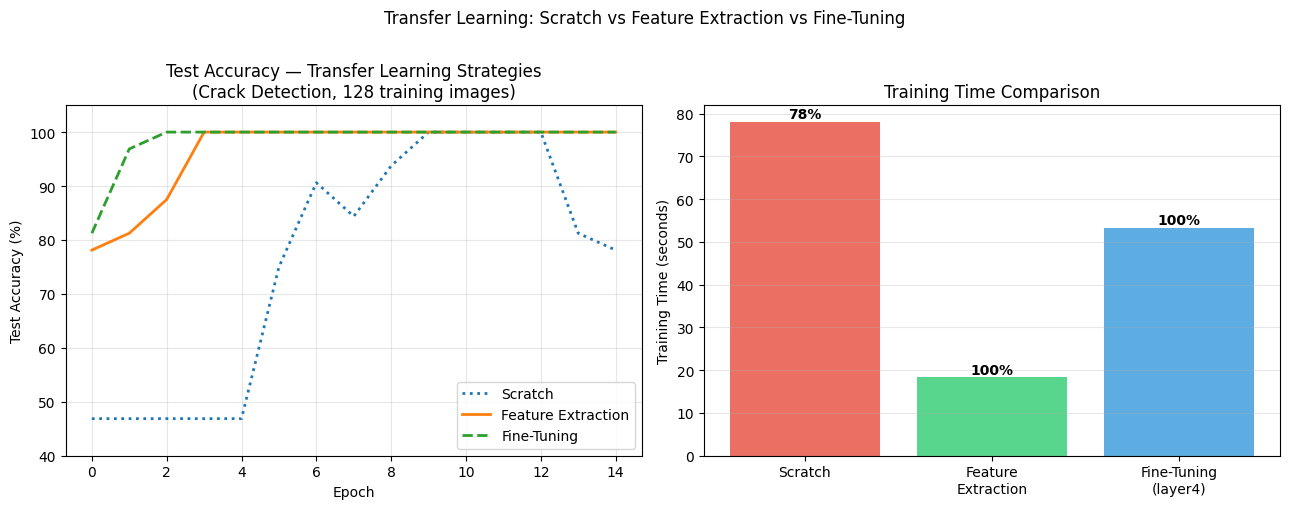


Summary:
Strategy                  | Test Acc   | Train Time   | Trainable Params    
---------------------------------------------------------------------------
Scratch                   |     78.1% |       78.1s | 11,177,538
Feature Extraction        |    100.0% |       18.3s | 1,026
Fine-Tuning (layer4)      |    100.0% |       53.3s | 8,394,754


In [8]:
# ─────────────────────────────────────────────────────────
# PART 8 — Comparison: Accuracy Curves + Training Time Bar
# ─────────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Test accuracy over epochs
ax = axes[0]
ax.plot([a*100 for a in te_sc], label='Scratch',           lw=2, linestyle=':')
ax.plot([a*100 for a in te_fe], label='Feature Extraction', lw=2)
ax.plot([a*100 for a in te_ft], label='Fine-Tuning',        lw=2, linestyle='--')
ax.set_xlabel('Epoch')
ax.set_ylabel('Test Accuracy (%)')
ax.set_title('Test Accuracy — Transfer Learning Strategies\n(Crack Detection, 128 training images)')
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_ylim(40, 105)

# Training time bar chart
ax2 = axes[1]
strategies  = ['Scratch', 'Feature\nExtraction', 'Fine-Tuning\n(layer4)']
times       = [t_sc, t_fe, t_ft]
final_accs  = [te_sc[-1]*100, te_fe[-1]*100, te_ft[-1]*100]
bars = ax2.bar(strategies, times, color=['#e74c3c', '#2ecc71', '#3498db'], alpha=0.8)
ax2.set_ylabel('Training Time (seconds)')
ax2.set_title('Training Time Comparison')
ax2.grid(True, alpha=0.3, axis='y')

# Annotate bars with final accuracy
for bar, acc in zip(bars, final_accs):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2,
             f'{acc:.0f}%', ha='center', va='bottom', fontweight='bold', fontsize=10)

plt.suptitle('Transfer Learning: Scratch vs Feature Extraction vs Fine-Tuning', y=1.01)
plt.tight_layout()
plt.show()

print("\nSummary:")
print(f"{'Strategy':25s} | {'Test Acc':10s} | {'Train Time':12s} | {'Trainable Params':<20s}")
print("-" * 75)
trainable_counts = [
    sum(p.numel() for p in model_sc.parameters() if p.requires_grad),
    sum(p.numel() for p in model_fe.parameters() if p.requires_grad),
    sum(p.numel() for p in model_ft.parameters() if p.requires_grad)
]
for s, acc, t, tp in zip(['Scratch', 'Feature Extraction', 'Fine-Tuning (layer4)'],
                          final_accs, times, trainable_counts):
    print(f"{s:25s} | {acc:8.1f}% | {t:10.1f}s | {tp:,}")

---
## Practice Exercises

1. **Unfreeze more layers** — In addition to `layer4`, also unfreeze `layer3`. Does test accuracy improve? What is the training time tradeoff?
2. **Learning rate sensitivity** — Try fine-tuning with `lr=1e-3` instead of `1e-4`. Does it cause instability (oscillating loss)? Why should fine-tuning use a lower LR?
3. **Augmentation** — Add random horizontal flips and brightness jitter to training images before fine-tuning. How does this affect the final accuracy on 128 training samples?
4. **VGG16 comparison** — Load `models.vgg16(weights=...)`, replace `model.classifier[6]` with `nn.Linear(4096, 2)`, freeze all, and compare feature extraction accuracy vs ResNet18.
5. **Confusion analysis** — After fine-tuning, find the test images the model misclassifies. Plot them. Do they have any common visual characteristics?

In [9]:
# ─────────────────────────────────────────────────────────
# PRACTICE — Starter code
# ─────────────────────────────────────────────────────────

# Exercise 4: VGG16 feature extraction
# try:
#     vgg16 = models.vgg16(weights=models.VGG16_Weights.DEFAULT)
# except AttributeError:
#     vgg16 = models.vgg16(pretrained=True)
#
# Freeze all
# for param in vgg16.parameters():
#     param.requires_grad = False
#
# Replace final classifier layer
# vgg16.classifier[6] = nn.Linear(4096, 2)
# tr_vgg, te_vgg, t_vgg = train_strategy(vgg16, 'VGG16 Feature Extract', epochs=EPOCHS)

# Exercise 5: Find misclassified test images
# model_ft.eval()
# with torch.no_grad():
#     for xb, yb in te_loader:
#         preds = model_ft(xb).argmax(1)
#         wrong_mask = (preds != yb)
#         if wrong_mask.any():
#             wrong_imgs = xb[wrong_mask]
#             wrong_true = yb[wrong_mask]
#             wrong_pred = preds[wrong_mask]
#             # De-normalise and display
#             # ...

print("Practice exercise starters are ready — uncomment and complete!")

Practice exercise starters are ready — uncomment and complete!


---
## ML Connection Table

| Scenario | Strategy | Why |
|---|---|---|
| 50–200 crack images | Feature Extraction (freeze all) | Too few samples to train conv layers |
| 500–2000 geo images | Fine-Tuning (unfreeze last block) | Enough data to adapt high-level features |
| 5000+ labelled images | Fine-Tuning (all layers) or Scratch | Large data justifies full adaptation |
| Very different domain (e.g., seismic waveforms) | Scratch or minimal transfer | Pretrained visual features less relevant |
| Identical domain (construction cracks) | Feature Extraction, fast convergence | ImageNet already has crack-like textures |

**VGG16 vs ResNet18 for geotechnical tasks:**
- ResNet18 is faster and achieves comparable accuracy
- VGG16 has a larger feature extractor (4096-dim) — can help with complex textures
- Both are good starting points; ResNet18 is the recommended default

---
## Key Takeaways

1. **Transfer learning is essential for geotechnical deep learning** — real projects rarely produce thousands of labelled images. A pretrained ResNet18 compensates for limited data by providing 11 million parameters already trained on diverse visual features.
2. **Feature extraction** (freeze all, train only the FC head) requires the fewest trainable parameters and training time, making it ideal for datasets under 200 images.
3. **Fine-tuning** with a low learning rate (1e-4) allows the last ResNet block to adapt to crack-specific patterns — balancing pretrained knowledge retention with task-specific adaptation.
4. **Training from scratch on small geo datasets almost always underperforms** — the model overfits to the limited training data before learning meaningful features.
5. Always apply **ImageNet normalisation** (mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225]) when using pretrained torchvision models — the pretrained weights assume this input distribution.

---
*Day 070 of 100 — Transfer learning lets millions of ImageNet images train your geotechnical model.*